<a href="https://colab.research.google.com/github/likithdr06/DLNN-lab-exp/blob/main/Exp_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense, Dropout

from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import classification_report, confusion_matrix

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("First review:", X_train[0][:20])
print("Sentiment:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
Sentiment: 1


In [ ]:
print("0 = Negative Review")
print("1 = Positive Review")

print("First 10 labels:", y_train[:10])

0 = Negative Review
1 = Positive Review
First 10 labels: [1 0 0 1 0 0 1 0 1 0]


In [ ]:
max_length = 200

X_train = pad_sequences(
    X_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


In [ ]:
lstm_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        input_length=max_length
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 67s 395ms/step - accuracy: 0.5155 - loss: 0.6931 - val_accuracy: 0.5010 - val_loss: 0.6924
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 78s 369ms/step - accuracy: 0.5278 - loss: 0.6862 - val_accuracy: 0.5534 - val_loss: 0.6822
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 84s 385ms/step - accuracy: 0.6245 - loss: 0.6311 - val_accuracy: 0.6406 - val_loss: 0.6355
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 57s 364ms/step - accuracy: 0.7599 - loss: 0.5217 - val_accuracy: 0.8004 - val_loss: 0.4798
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 84s 376ms/step - accuracy: 0.8034 - loss: 0.4813 - val_accuracy: 0.8166 - val_loss: 0.4757


In [ ]:
lstm_loss, lstm_accuracy = lstm_model.evaluate(
    X_test, y_test
)

print("LSTM Test Loss:", lstm_loss)
print("LSTM Test Accuracy:", lstm_accuracy * 100, "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step - accuracy: 0.7977 - loss: 0.5039
LSTM Test Loss: 0.5038952827453613
LSTM Test Accuracy: 79.77200150489807 %


In [ ]:
gru_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        input_length=max_length
    ),

    GRU(64),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

gru_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

gru_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 69s 423ms/step - accuracy: 0.5024 - loss: 0.6930 - val_accuracy: 0.5096 - val_loss: 0.6921
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 82s 423ms/step - accuracy: 0.5734 - loss: 0.6616 - val_accuracy: 0.6128 - val_loss: 0.6445


In [ ]:
gru_loss, gru_accuracy = gru_model.evaluate(
    X_test, y_test
)

print("GRU Test Loss:", gru_loss)
print("GRU Test Accuracy:", gru_accuracy * 100, "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 24s 30ms/step - accuracy: 0.5073 - loss: 0.6922
GRU Test Loss: 0.6921722888946533
GRU Test Accuracy: 50.731998682022095 %


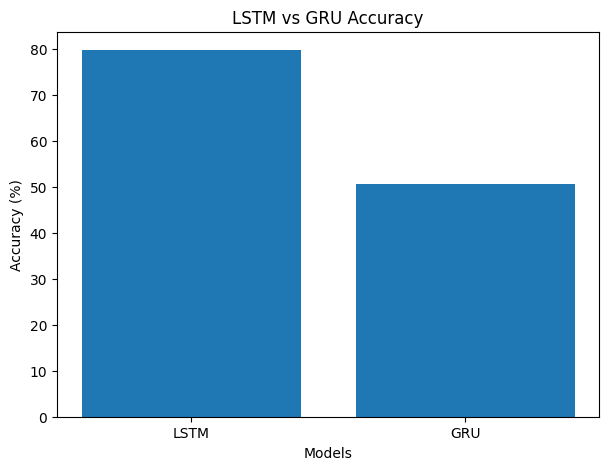

LSTM Accuracy: 79.77 %
GRU Accuracy: 50.73 %


In [ ]:
models = ['LSTM', 'GRU']

accuracies = [
    lstm_accuracy * 100,
    gru_accuracy * 100
]

plt.figure(figsize=(7, 5))

plt.bar(models, accuracies)

plt.title("LSTM vs GRU Accuracy")
plt.xlabel("Models")
plt.ylabel("Accuracy (%)")

plt.show()

for model, accuracy in zip(models, accuracies):
    print(model, "Accuracy:", round(accuracy, 2), "%")

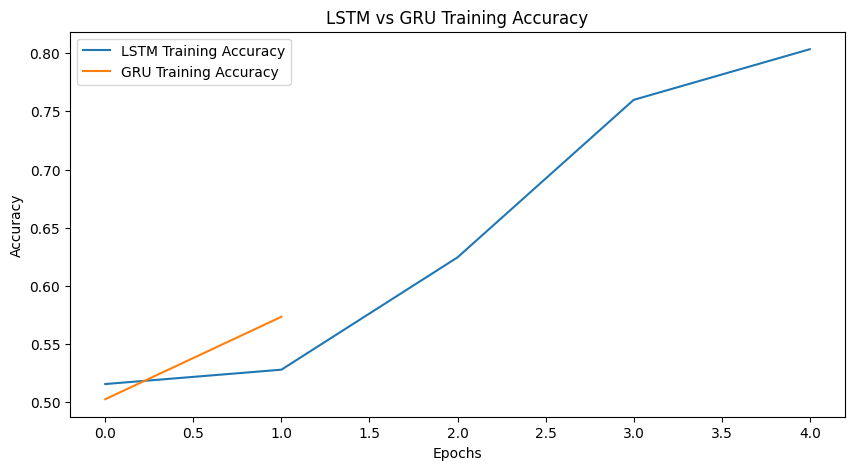

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    lstm_history.history['accuracy'],
    label='LSTM Training Accuracy'
)

plt.plot(
    gru_history.history['accuracy'],
    label='GRU Training Accuracy'
)

plt.title("LSTM vs GRU Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

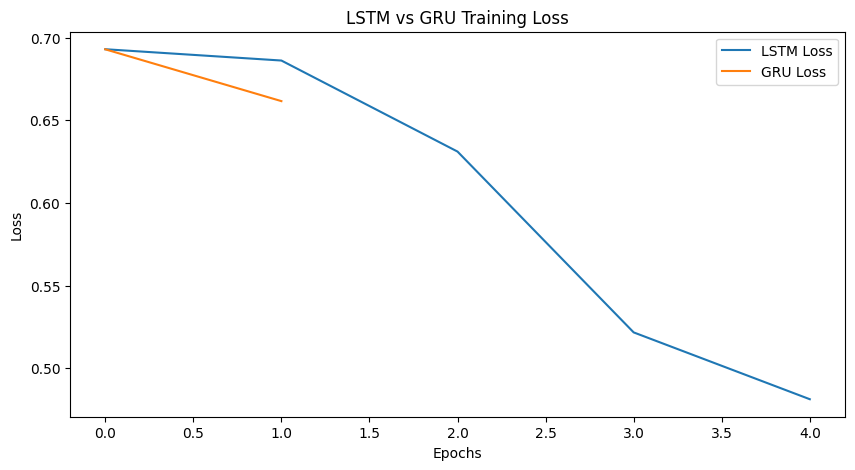

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    lstm_history.history['loss'],
    label='LSTM Loss'
)

plt.plot(
    gru_history.history['loss'],
    label='GRU Loss'
)

plt.title("LSTM vs GRU Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [ ]:
y_pred = (gru_model.predict(X_test) > 0.5).astype("int32")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.65      0.57     12500
           1       0.51      0.37      0.43     12500

    accuracy                           0.51     25000
   macro avg       0.51      0.51      0.50     25000
weighted avg       0.51      0.51      0.50     25000

Confusion Matrix:
[[8097 4403]
 [7914 4586]]


In [ ]:
word_index = imdb.get_word_index()

def predict_sentiment(review):
    words = review.lower().split()
    sequence = [1]

    for word in words:
        index = word_index.get(word, 2) + 3
        if index >= vocab_size:
            index = 2
        sequence.append(index)

    padded = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

    # Using the better performing lstm_model instead of gru_model
    prediction = lstm_model.predict(padded, verbose=0)[0][0]

    if prediction >= 0.5:
        print("Positive Review")
    else:
        print("Negative Review")

    print("Sentiment Score:", round(float(prediction), 4))

predict_sentiment(
    "This movie is excellent and wonderful. I really enjoyed it"
)

Positive Review
Sentiment Score: 0.8707


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix

# 1. Configuration Parameters
vocab_size = 10000
max_length = 200

# 2. Load and preprocess the IMDB dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=vocab_size)

X_train = pad_sequences(X_train, maxlen=max_length, padding='post', truncating='post')
X_test = pad_sequences(X_test, maxlen=max_length, padding='post', truncating='post')

# 3. Build the optimal LSTM model architecture
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 4. Train the model with early stopping to prevent overfitting
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

print("Training the LSTM model...")
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop]
)

# 5. Evaluate the model on test data
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nLSTM Test Accuracy: {accuracy * 100:.2f}%")

# 6. Sentiment prediction function for custom reviews
word_index = imdb.get_word_index()

def predict_sentiment(review):
    words = review.lower().split()
    sequence = [1]

    for word in words:
        index = word_index.get(word, 2) + 3
        if index >= vocab_size:
            index = 2
        sequence.append(index)

    padded = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

    prediction = model.predict(padded, verbose=0)[0][0]

    print(f"\nReview: \"{review}\"")
    if prediction >= 0.5:
        print("Sentiment: Positive Review")
    else:
        print("Sentiment: Negative Review")
    print("Confidence Score:", round(float(prediction), 4))

# 7. Test prediction
predict_sentiment("This movie is excellent and wonderful. I really enjoyed it")

Training the LSTM model...
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 61s 373ms/step - accuracy: 0.5108 - loss: 0.6925 - val_accuracy: 0.4942 - val_loss: 0.6923
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 60s 383ms/step - accuracy: 0.5337 - loss: 0.6853 - val_accuracy: 0.5600 - val_loss: 0.6742
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 58s 371ms/step - accuracy: 0.6220 - loss: 0.6139 - val_accuracy: 0.5884 - val_loss: 0.6408
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 59s 376ms/step - accuracy: 0.6658 - loss: 0.5436 - val_accuracy: 0.6338 - val_loss: 0.5867
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 58s 368ms/step - accuracy: 0.7862 - loss: 0.4268 - val_accuracy: 0.8306 - val_loss: 0.4316

LSTM Test Accuracy: 81.22%

Review: "This movie is excellent and wonderful. I really enjoyed it"
Sentiment: Positive Review
Confidence Score: 0.8472
